# Tuần 1: Chuẩn bị dữ liệu và EDA NEU Surface Defect

**Mục tiêu:** kiểm tra dữ liệu NEU-DET cho bài toán phát hiện lỗi bề mặt thép bằng YOLOv8.

NEU-DET chỉ có nhãn bounding box theo định dạng YOLO, **không có mask phân vùng**. Vì vậy, dữ liệu này được dùng cho phần Detection ở Tuần 2; Tuần 3 dùng MVTec AD bottle để phân vùng lỗi chi tiết.

**Đầu ra Tuần 1**
- `thong_ke_anh_va_nhan.csv`: số lượng ảnh và số bounding box.
- `phan_bo_loi_tieng_viet.png`: biểu đồ phân bố sáu loại lỗi.
- `mau_bbox_tieng_viet.png`: ảnh mẫu có khung bao và nhãn tiếng Việt.
- `bao_cao_kiem_tra_du_lieu.csv`: lỗi cấu trúc hoặc nhãn không hợp lệ.
- `configs/neu_det.yaml`: cấu hình dữ liệu cho YOLOv8.


In [1]:
from pathlib import Path
from zipfile import ZipFile, BadZipFile
import os
import sys
import random
import subprocess

SEED = 42
random.seed(SEED)

CWD = Path.cwd().resolve()
IS_KAGGLE = Path("/kaggle").exists()
KAGGLE_WORKING = Path("/kaggle/working")
KAGGLE_INPUT = Path("/kaggle/input")


def looks_like_project(path: Path) -> bool:
    return (path / "notebooks").is_dir() and (path / "datasets").is_dir()


def safe_extract_project_zip():
    """
    Nếu project ZIP được gắn qua Kaggle Input, giải nén đúng một lần vào
    /kaggle/working/Industrial_Defect_VQA để notebook có quyền ghi output.
    """
    if not IS_KAGGLE or not KAGGLE_INPUT.is_dir():
        return None

    target = KAGGLE_WORKING / "Industrial_Defect_VQA"
    if looks_like_project(target):
        return target

    for zip_path in KAGGLE_INPUT.glob("**/*.zip"):
        try:
            with ZipFile(zip_path) as archive:
                names = [name.replace("\\", "/") for name in archive.namelist()]
                has_neu = any("NEU-DET/train/images/" in name for name in names)
                has_notebooks = any("/notebooks/" in name or name.startswith("notebooks/") for name in names)
                if not (has_neu and has_notebooks):
                    continue
                target.mkdir(parents=True, exist_ok=True)
                marker = target / f".extracted_{zip_path.stem}"
                if not marker.exists():
                    archive.extractall(target)
                    marker.touch()
                if looks_like_project(target):
                    return target
                # Một số ZIP có thêm thư mục bọc ngoài. Dùng trực tiếp thư mục này,
                # không di chuyển file để tránh ghi đè sai cấu trúc.
                nested = [p for p in target.iterdir() if p.is_dir() and looks_like_project(p)]
                if nested:
                    return nested[0]
        except (BadZipFile, OSError):
            continue
    return None


def find_project_root() -> Path:
    extracted = safe_extract_project_zip()
    candidates = []
    if extracted is not None:
        candidates.append(extracted)
    candidates += [CWD, *CWD.parents]
    kaggle_project = KAGGLE_WORKING / "Industrial_Defect_VQA"
    if kaggle_project.exists():
        candidates.insert(0, kaggle_project)

    checked = set()
    for candidate in candidates:
        try:
            candidate = candidate.resolve()
        except OSError:
            continue
        if str(candidate) in checked:
            continue
        checked.add(str(candidate))
        if looks_like_project(candidate):
            return candidate
    return CWD


def is_neu_root(path: Path) -> bool:
    return (
        path.is_dir()
        and (path / "train" / "images").is_dir()
        and (path / "train" / "labels").is_dir()
        and (path / "test" / "images").is_dir()
        and (path / "test" / "labels").is_dir()
    )


def find_neu_root(project_root: Path):
    checked = []
    candidates = [
        project_root / "datasets" / "detection_yolov8_neu" / "data" / "NEU-DET",
        project_root / "data" / "NEU-DET",
    ]
    for candidate in candidates:
        checked.append(candidate)
        if is_neu_root(candidate):
            return candidate.resolve(), checked

    if KAGGLE_INPUT.is_dir():
        for candidate in KAGGLE_INPUT.glob("**/NEU-DET"):
            checked.append(candidate)
            if is_neu_root(candidate):
                return candidate.resolve(), checked
        for train_images in KAGGLE_INPUT.glob("**/train/images"):
            candidate = train_images.parent.parent
            checked.append(candidate)
            if is_neu_root(candidate):
                return candidate.resolve(), checked
    return None, checked


def find_mvtec_root(category: str = "bottle"):
    checked = []
    project_root = find_project_root()
    direct = [
        project_root / "data" / "mvtec_ad",
        project_root / "data" / "MVTec_AD",
    ]
    for candidate in direct:
        checked.append(candidate)
        if (candidate / category / "test").is_dir() and (candidate / category / "ground_truth").is_dir():
            return candidate.resolve(), checked

    if KAGGLE_INPUT.is_dir():
        for candidate in KAGGLE_INPUT.glob("**/" + category):
            checked.append(candidate)
            if (candidate / "test").is_dir() and (candidate / "ground_truth").is_dir():
                return candidate.parent.resolve(), checked
    return None, checked


def get_write_root(project_root: Path) -> Path:
    """
    Kaggle Input chỉ đọc. Mọi YAML, split, checkpoint và output phải ghi vào
    /kaggle/working. Khi chạy local, ghi trực tiếp trong project.
    """
    root = (KAGGLE_WORKING / "Industrial_Defect_VQA_runtime") if IS_KAGGLE else project_root
    root.mkdir(parents=True, exist_ok=True)
    return root


def gpu_status():
    try:
        import torch
        cuda_ok = bool(torch.cuda.is_available())
        gpu_name = torch.cuda.get_device_name(0) if cuda_ok else "Không có GPU"
    except Exception:
        cuda_ok, gpu_name = False, "Không kiểm tra được GPU"
    print("CWD:", CWD)
    print("Kaggle runtime:", IS_KAGGLE)
    print("CUDA available:", cuda_ok)
    print("GPU name:", gpu_name)
    try:
        print(subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
            text=True
        ).strip())
    except Exception:
        print("nvidia-smi: không khả dụng")
    return cuda_ok


PROJECT_ROOT = find_project_root()
WRITE_ROOT = get_write_root(PROJECT_ROOT)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("WRITE_ROOT:", WRITE_ROOT)


PROJECT_ROOT: /kaggle/working
WRITE_ROOT: /kaggle/working/Industrial_Defect_VQA_runtime


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import cv2
import yaml

plt.rcParams["font.family"] = "DejaVu Sans"

CLASSES_EN = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches",
]
CLASSES_VI = {
    0: "Nứt rạn",
    1: "Tạp chất lẫn",
    2: "Vết vá",
    3: "Rỗ bề mặt",
    4: "Vảy cán",
    5: "Trầy xước",
}
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}

NEU_ROOT, CHECKED_PATHS = find_neu_root(PROJECT_ROOT)
HAS_NEU = NEU_ROOT is not None

OUTPUT_DIR = WRITE_ROOT / "outputs" / "week01_eda"
CONFIG_DIR = WRITE_ROOT / "configs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

if HAS_NEU:
    print("Đã tìm thấy NEU-DET:", NEU_ROOT)
else:
    print("Chưa tìm thấy NEU-DET. Notebook sẽ dừng phần EDA một cách an toàn.")
    print("Đường dẫn đã kiểm tra:")
    for path in CHECKED_PATHS[:20]:
        print(" -", path)
    print("VSCode: đặt dữ liệu tại datasets/detection_yolov8_neu/data/NEU-DET.")
    print("Kaggle: Add Data cho dataset NEU-DET hoặc gắn ZIP chứa toàn bộ project.")


Đã tìm thấy NEU-DET: /kaggle/input/datasets/apexpython/industrial-defect-vqa-kaggle/external/detection_yolov8_neu/data/NEU-DET


## 1. Kiểm tra cấu trúc dữ liệu và nhãn YOLO


In [3]:
def list_images(split: str):
    if not HAS_NEU:
        return []
    folder = NEU_ROOT / split / "images"
    return sorted(path for path in folder.iterdir() if path.suffix.lower() in IMAGE_SUFFIXES)


def parse_yolo_label(label_path: Path):
    records, errors = [], []
    if not label_path.exists():
        return records, ["Thiếu file nhãn"]

    for line_number, line in enumerate(label_path.read_text(encoding="utf-8", errors="replace").splitlines(), start=1):
        line = line.strip()
        if not line:
            continue
        values = line.split()
        if len(values) != 5:
            errors.append(f"Dòng {line_number}: phải có 5 giá trị")
            continue
        try:
            class_id = int(float(values[0]))
            x_center, y_center, width, height = map(float, values[1:])
        except ValueError:
            errors.append(f"Dòng {line_number}: không đọc được giá trị số")
            continue

        if not 0 <= class_id < len(CLASSES_EN):
            errors.append(f"Dòng {line_number}: class_id không hợp lệ")
        if not all(0.0 <= value <= 1.0 for value in [x_center, y_center, width, height]):
            errors.append(f"Dòng {line_number}: tọa độ YOLO ngoài khoảng [0, 1]")

        records.append({
            "class_id": class_id,
            "class_name_en": CLASSES_EN[class_id] if 0 <= class_id < len(CLASSES_EN) else "invalid",
            "class_name_vi": CLASSES_VI.get(class_id, "Không xác định"),
            "x_center": x_center,
            "y_center": y_center,
            "width": width,
            "height": height,
        })
    return records, errors


label_rows, integrity_rows = [], []
if HAS_NEU:
    for split in ["train", "test"]:
        images = list_images(split)
        label_dir = NEU_ROOT / split / "labels"
        image_stems = {path.stem for path in images}
        label_stems = {path.stem for path in label_dir.glob("*.txt")}

        for stem in sorted(image_stems - label_stems):
            integrity_rows.append({"tap_du_lieu": split, "tep": stem, "van_de": "Ảnh không có nhãn"})
        for stem in sorted(label_stems - image_stems):
            integrity_rows.append({"tap_du_lieu": split, "tep": stem, "van_de": "Nhãn không có ảnh"})

        for image_path in images:
            records, errors = parse_yolo_label(label_dir / f"{image_path.stem}.txt")
            if errors:
                integrity_rows.append({
                    "tap_du_lieu": split,
                    "tep": image_path.name,
                    "van_de": "; ".join(errors),
                })
            for record in records:
                label_rows.append({"tap_du_lieu": split, "anh": image_path.name, **record})

labels_df = pd.DataFrame(label_rows)
integrity_df = pd.DataFrame(integrity_rows)
image_count_df = pd.DataFrame([
    {"tap_du_lieu": split, "so_anh": len(list_images(split))}
    for split in ["train", "test"]
])

if not labels_df.empty:
    distribution_df = (
        labels_df.groupby(["tap_du_lieu", "class_id", "class_name_vi"])
        .size()
        .reset_index(name="so_bounding_box")
        .sort_values(["tap_du_lieu", "class_id"])
    )
else:
    distribution_df = pd.DataFrame(columns=["tap_du_lieu", "class_id", "class_name_vi", "so_bounding_box"])

pd.concat([
    image_count_df.assign(loai_thong_ke="Số ảnh"),
    pd.DataFrame([{
        "tap_du_lieu": "Tổng",
        "so_anh": int(image_count_df["so_anh"].sum()) if not image_count_df.empty else 0,
        "loai_thong_ke": "Số ảnh",
    }]),
], ignore_index=True).to_csv(OUTPUT_DIR / "thong_ke_anh_va_nhan.csv", index=False)

distribution_df.to_csv(OUTPUT_DIR / "phan_bo_nhan_theo_lop.csv", index=False)
integrity_df.to_csv(OUTPUT_DIR / "bao_cao_kiem_tra_du_lieu.csv", index=False)

display(image_count_df)
display(distribution_df)
display(integrity_df if not integrity_df.empty else pd.DataFrame([{"trang_thai": "Không phát hiện lỗi cấu trúc"}]))


,tap_du_lieu,so_anh
0,train,1620
1,test,180


,tap_du_lieu,class_id,class_name_vi,so_bounding_box
0,test,0,Nứt rạn,79
1,test,1,Tạp chất lẫn,89
2,test,2,Vết vá,99
3,test,3,Rỗ bề mặt,46
4,test,4,Vảy cán,69
5,test,5,Trầy xước,64
6,train,0,Nứt rạn,610
7,train,1,Tạp chất lẫn,922
8,train,2,Vết vá,782
9,train,3,Rỗ bề mặt,386


,trang_thai
0,Không phát hiện lỗi cấu trúc


## 2. Biểu đồ phân bố sáu loại lỗi bằng tiếng Việt


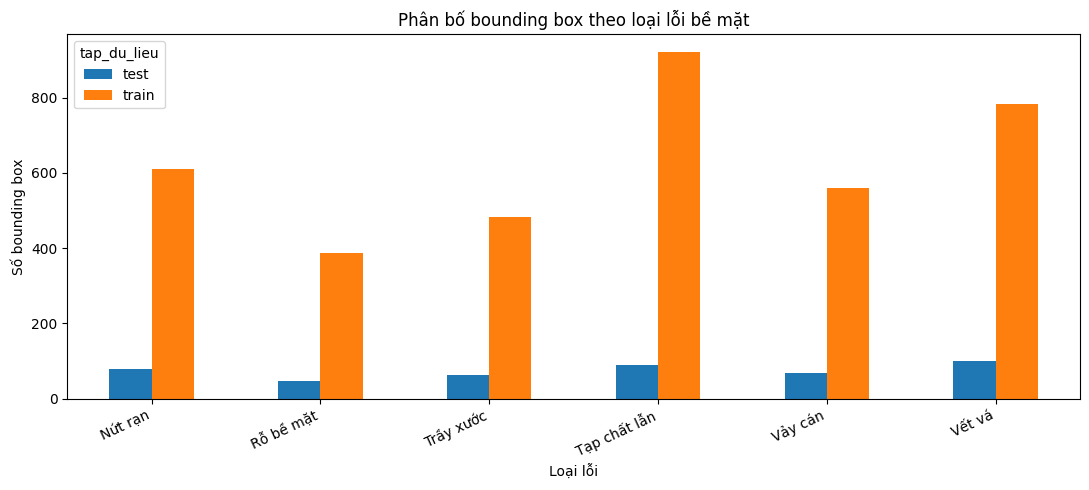

In [4]:
if not distribution_df.empty:
    chart_df = distribution_df.pivot(
        index="class_name_vi", columns="tap_du_lieu", values="so_bounding_box"
    ).fillna(0)

    ax = chart_df.plot(kind="bar", figsize=(11, 5))
    ax.set_title("Phân bố bounding box theo loại lỗi bề mặt")
    ax.set_xlabel("Loại lỗi")
    ax.set_ylabel("Số bounding box")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "phan_bo_loi_tieng_viet.png", dpi=160)
    plt.show()
else:
    print("Chưa có dữ liệu để vẽ biểu đồ.")


## 3. Tạo cấu hình dữ liệu cho YOLOv8


In [5]:
DATA_YAML = CONFIG_DIR / "neu_det.yaml"

if HAS_NEU:
    config = {
        "path": str(NEU_ROOT.resolve()),
        "train": "train/images",
        "val": "test/images",
        "test": "test/images",
        "names": {index: name for index, name in enumerate(CLASSES_EN)},
    }
    with DATA_YAML.open("w", encoding="utf-8") as file:
        yaml.safe_dump(config, file, allow_unicode=True, sort_keys=False)

    print("Đã tạo cấu hình:", DATA_YAML)
    print(DATA_YAML.read_text(encoding="utf-8"))
else:
    print("Chưa tạo YAML vì NEU-DET chưa khả dụng.")


Đã tạo cấu hình: /kaggle/working/Industrial_Defect_VQA_runtime/configs/neu_det.yaml
path: /kaggle/input/datasets/apexpython/industrial-defect-vqa-kaggle/external/detection_yolov8_neu/data/NEU-DET
train: train/images
val: test/images
test: test/images
names:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches



## 4. Hiển thị ảnh mẫu cùng bounding box và nhãn tiếng Việt


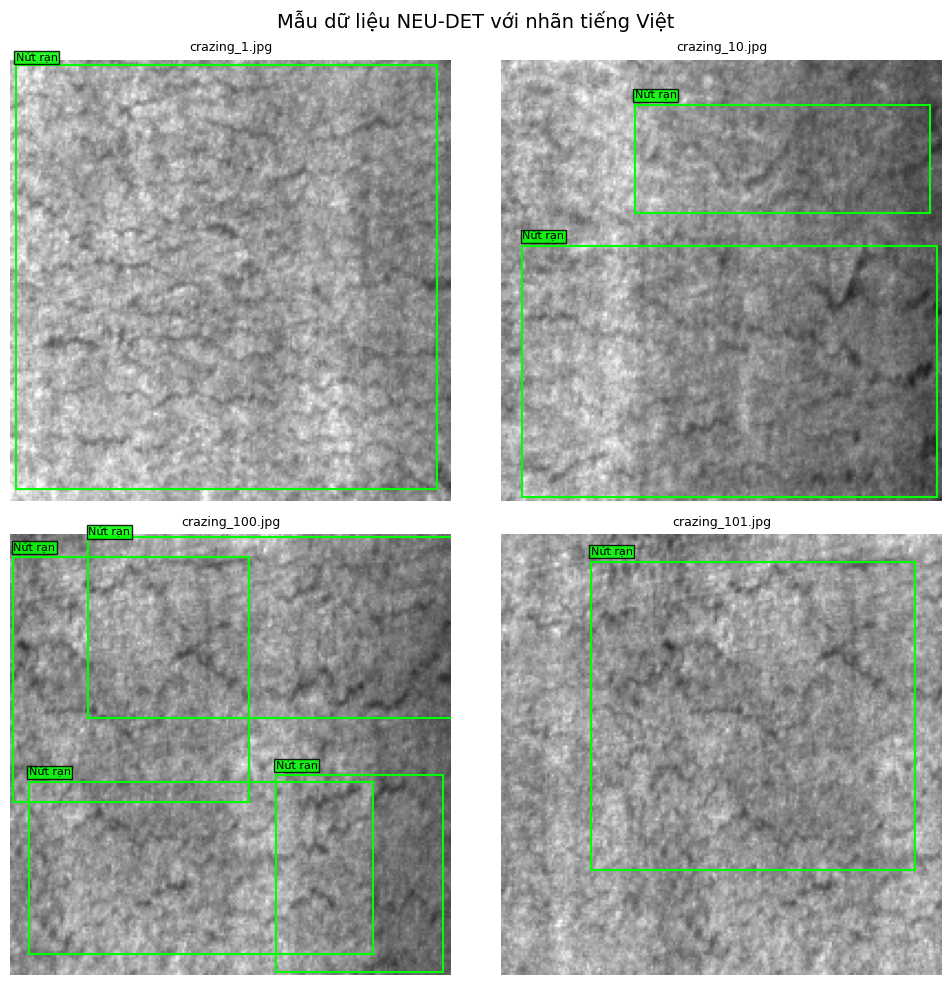

In [6]:
def draw_ground_truth(ax, image_path: Path, label_path: Path):
    image_bgr = cv2.imread(str(image_path))
    if image_bgr is None:
        raise ValueError(f"Không đọc được ảnh: {image_path}")

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    image_height, image_width = image_rgb.shape[:2]
    ax.imshow(image_rgb)
    ax.set_title(image_path.name, fontsize=9)

    records, _ = parse_yolo_label(label_path)
    for record in records:
        x = (record["x_center"] - record["width"] / 2) * image_width
        y = (record["y_center"] - record["height"] / 2) * image_height
        width = record["width"] * image_width
        height = record["height"] * image_height
        ax.add_patch(Rectangle((x, y), width, height, fill=False, edgecolor="lime", linewidth=1.5))
        ax.text(x, max(0, y - 3), record["class_name_vi"], color="black",
                bbox={"facecolor": "lime", "alpha": 0.85, "pad": 1}, fontsize=8)
    ax.axis("off")


if HAS_NEU:
    samples = list_images("train")[:4]
    if samples:
        fig, axes = plt.subplots(2, 2, figsize=(10, 10))
        for ax, image_path in zip(axes.ravel(), samples):
            draw_ground_truth(ax, image_path, NEU_ROOT / "train" / "labels" / f"{image_path.stem}.txt")
        for ax in axes.ravel()[len(samples):]:
            ax.axis("off")
        fig.suptitle("Mẫu dữ liệu NEU-DET với nhãn tiếng Việt", fontsize=14)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "mau_bbox_tieng_viet.png", dpi=160)
        plt.show()
else:
    print("Chưa thể hiển thị ảnh vì thiếu NEU-DET.")


## Hoàn thành Tuần 1

Chỉ khi các file trong `outputs/week01_eda/` được sinh ra thì Tuần 1 mới có bằng chứng dữ liệu đầu ra. Tuần 2 sẽ tự tách train/validation từ tập train của NEU-DET, không dùng tập test làm validation.
